# 05 · Running on the sun — and the moon

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EngMtaleb/chemai/blob/main/projects/p04_tide_fouling/notebooks/05_sun_and_moon_design.ipynb)

The record says the pre-treatment does not mind when it runs (notebook 04). So a seawater plant can
follow the sun. How much does that take — production capacity, a water tank, solar panels — and
what does a tidal turbine add? And how would you check your own plant's log for a tide?

This part is a **design study on a synthetic year**, not a measurement: no site, no prices.

**Data:** a public seawater ultrafiltration (UF) pilot record, pre-treatment for a reverse-osmosis pilot, 2012–2015: Zenodo [4630769](https://zenodo.org/records/4630769), also Dryad [doi:10.5068/D1310B](https://doi.org/10.5068/D1310B), CC0. The site is not named here. The notebooks read the tables committed in `results/`; the 356 MB raw archive is needed only where a cell says so.

Script version: `step7a_uf_energy.py`, `step7_solar_plan.py`, `step8_sun_and_moon.py` · record:
`VALIDATION.md`, sections 8–10.

In [1]:
# Setup. In Google Colab this clones the repository and installs the package (about a minute).
# On your own machine, run from a clone after:  pip install -e ".[viz,data]"
import os, subprocess, sys
from pathlib import Path
REF = "main"        # before the Project 4 pull request is merged, use "p04-tide-fouling"
if "google.colab" in sys.modules:
    if not Path("/content/chemai").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1", "--branch", REF,
                        "https://github.com/EngMtaleb/chemai.git", "/content/chemai"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "/content/chemai[viz,data]"], check=True)
    sys.path.insert(0, "/content/chemai")
    ROOT = Path("/content/chemai")
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
P4 = ROOT / "projects" / "p04_tide_fouling"
RES = P4 / "results"

import json, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140)
INK, MUTED, BLUE, ORANGE, GREEN, RED, SUN = "#1f2933", "#7b8794", "#2f6fb2", "#d9822b", "#3f8f5a", "#c23b3b", "#f2c14e"

def load(name):
    """A committed result file from projects/p04_tide_fouling/results/."""
    return json.loads((RES / name).read_text())

## 1. How much energy a cubic metre of water takes

Reverse osmosis is taken from the literature: 3.0 kWh per m³ of product. The pre-treatment comes from
the record (`step7a_uf_energy.py`): the pressure times the flow the pumps had to deliver, filtering
and backwashing, per m³ of feed — then divided by a pump efficiency and by the RO recovery, because
2.2 m³ of seawater are filtered for every m³ of product.

In [2]:
from chemai.models.solar_plan import SolarPlanConfig, flux_penalty, plan_lp, plan_rule, pv_year, tidal_year
e = load("step7a_uf_energy.json")
cfg = SolarPlanConfig()
hyd = e["kwh_per_m3_uf_feed_hydraulic"]
print(f"UF hydraulic energy: {hyd['median']:.3f} kWh per m³ of feed (middle half {hyd['iqr'][0]:.3f}-{hyd['iqr'][1]:.3f}, {e['runs_used']} runs)")
print(f"per m³ of product: / {e['assumed']['pump_efficiency']} / {e['assumed']['ro_recovery']} = {e['kwh_per_m3_product']:.2f} kWh "
      f"({e['kwh_per_m3_product_if_backwash_from_ro_feed']:.2f} if the backwash water came out of the RO feed)")
print(f"the plant: {cfg.sec_ro_kwh_m3} (RO) + {cfg.sec_uf_kwh_m3} (UF) = {cfg.sec:.2f} kWh per m³")

UF hydraulic energy: 0.083 kWh per m³ of feed (middle half 0.075-0.089, 106 runs)
per m³ of product: / 0.7 / 0.45 = 0.26 kWh (0.37 if the backwash water came out of the RO feed)
the plant: 3.0 (RO) + 0.26 (UF) = 3.26 kWh per m³


## 2. The sun, hour by hour

A synthetic year: day length and clear-sky yield follow the seasons, and each day draws a cloud
cover. No site is modelled — the point is the shape: a day, a night, and some dull days.

mean 5.26 kWh per kWp a day; dullest day 0.84, brightest 7.06


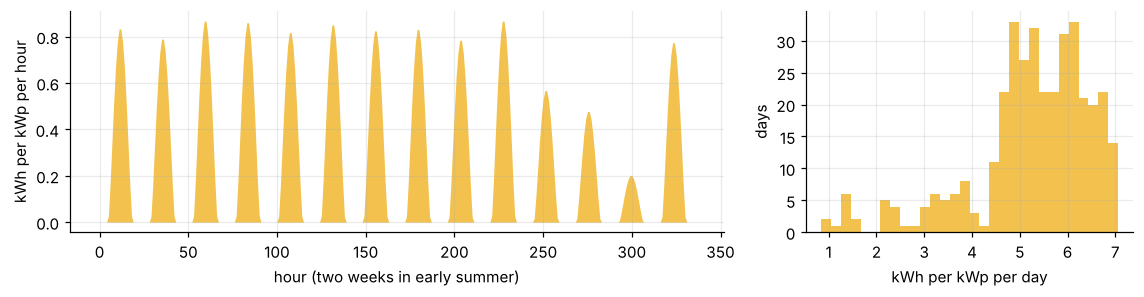

In [3]:
pv = pv_year(cfg)
daily = pv.reshape(-1, 24).sum(1)
print(f"mean {daily.mean():.2f} kWh per kWp a day; dullest day {daily.min():.2f}, brightest {daily.max():.2f}")
fig, ax = plt.subplots(1, 2, figsize=(10.5, 2.8), gridspec_kw={"width_ratios": [2, 1]})
ax[0].fill_between(np.arange(14 * 24), pv[172 * 24:186 * 24], color=SUN, lw=0)
ax[0].set_xlabel("hour (two weeks in early summer)"); ax[0].set_ylabel("kWh per kWp per hour")
ax[1].hist(daily, bins=30, color=SUN); ax[1].set_xlabel("kWh per kWp per day"); ax[1].set_ylabel("days")
plt.tight_layout(); plt.show()

## 3. One design, one year

Per m³/day of average demand: a plant that can make **3×** the average rate (so it can make a day's
water in 8 hours), a tank holding **16 hours** of demand, and **0.7 kWp** of PV. The modules switch on
and off at their usual flux — the condition under which notebook 04's result applies. A linear
programme finds the least grid energy any controller could achieve with the whole year known in
advance; a simple rule with no forecast runs beside it.

best possible: 93.0% of the energy from the sun, grid 0.23 kWh/m³ (from 3.26); 18% of the PV energy unused; runs 8.0 h a day
no-forecast rule: 92.5%


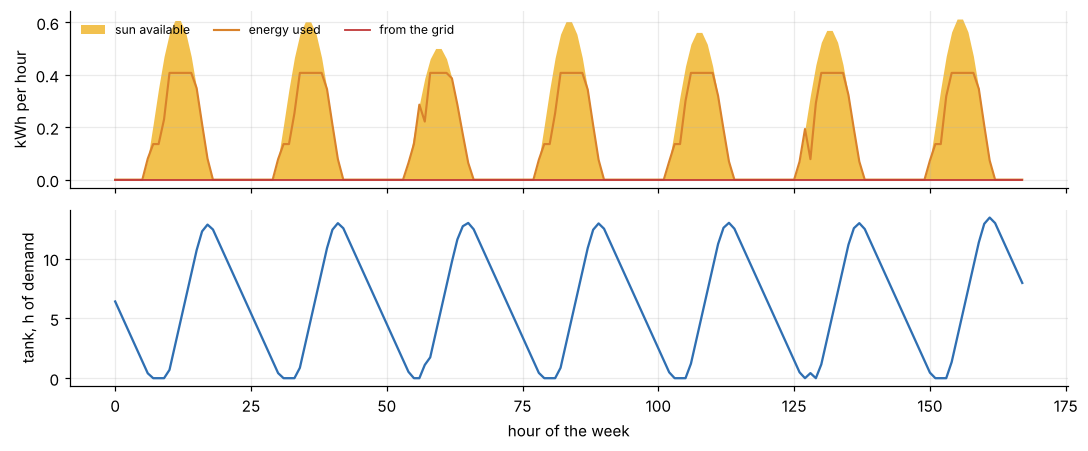

In [4]:
lp, s = plan_lp(pv, 3.0, 16, 0.7, cfg, series=True)
rule = plan_rule(pv, 3.0, 16, 0.7, cfg)
print(f"best possible: {lp.solar_fraction:.1%} of the energy from the sun, grid {lp.grid_kwh_m3:.2f} kWh/m³ "
      f"(from {cfg.sec:.2f}); {lp.curtailed_share:.0%} of the PV energy unused; runs {lp.run_hours_per_day:.1f} h a day")
print(f"no-forecast rule: {rule.solar_fraction:.1%}")
start = 236 * 24
sl, h = slice(start, start + 7 * 24), np.arange(7 * 24)
fig, ax = plt.subplots(2, 1, figsize=(10, 4.2), sharex=True)
ax[0].fill_between(h, s["pv_kwh"][sl], color=SUN, lw=0, label="sun available")
ax[0].plot(h, s["production_m3"][sl] * cfg.sec, color=ORANGE, lw=1.4, label="energy used")
ax[0].plot(h, s["grid_kwh"][sl], color=RED, lw=1.2, label="from the grid")
ax[0].set_ylabel("kWh per hour"); ax[0].legend(frameon=False, fontsize=8, ncol=3, loc="upper left")
ax[1].plot(h, s["tank_m3"][sl] * 24, color=BLUE); ax[1].set_ylabel("tank, h of demand")
ax[1].set_xlabel("hour of the week")
plt.tight_layout(); plt.show()

The plant makes its water while the sun shines; the tank carries the night; the grid fills in
only after dull days.

## 4. Every design

`step7_solar_plan.py` ran 192 designs × 2 weathers (about two minutes); its table is committed.

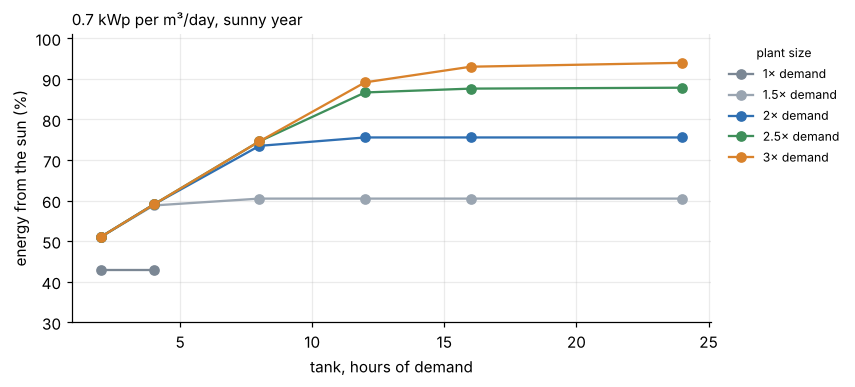

,capacity,storage_h,pv_kwp,solar_fraction,curtailed_share
50%,1.5,4.0,0.5,0.554,0.313
75%,2.5,12.0,0.5,0.761,0.056
90%,3.0,16.0,0.7,0.930,0.176
95%,3.0,16.0,0.9,0.969,0.333


In [5]:
df = pd.read_parquet(RES / "step7_solar_plan.parquet")
sunny = df[df.weather == "sunny"]
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for c, col in zip((1.0, 1.5, 2.0, 2.5, 3.0), (MUTED, "#9aa5b1", BLUE, GREEN, ORANGE)):
    d = sunny[(sunny.capacity == c) & (sunny.pv_kwp == 0.7)].sort_values("storage_h")
    ax.plot(d.storage_h, d.solar_fraction * 100, "o-", color=col, label=f"{c:g}× demand")
ax.set_xlabel("tank, hours of demand"); ax.set_ylabel("energy from the sun (%)"); ax.set_ylim(30, 101)
ax.legend(frameon=False, fontsize=8, title="plant size", title_fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_title("0.7 kWp per m³/day, sunny year", loc="left", fontsize=10)
plt.show()
summary = load("step7_solar_plan.json")["weather"]["sunny"]
pd.DataFrame(summary["smallest_design"]).T[["capacity", "storage_h", "pv_kwp", "solar_fraction", "curtailed_share"]].round(3)

- A plant sized for round-the-clock running (1×) has to run at night: it stops near **46 %** solar
  however much PV is added. **Capacity and a tank** buy the rest.
- **Forecasts matter only for small tanks.** With 12 hours of storage or more, the no-forecast rule
  matches the perfect plan in the median design; with 2–4 hours it loses 7–8 points.

In [6]:
df["gap"] = df.solar_fraction - df.rule_solar_fraction
(df.groupby("storage_h").gap.median() * 100).round(1).rename("rule behind the plan, points (median design)").to_frame().T

storage_h,2,4,8,12,16,24
"rule behind the plan, points (median design)",7.9,6.9,1.5,0.0,0.0,0.0


## 5. Add modules — do not push the flux

The cheaper-looking way to get 3× capacity is to run the same membranes 3× faster in daylight. The
record's no-penalty result was measured at the usual flux; if the fouling rate grows like flux^n,
fouling per m³ grows like flux^(n−1):

In [7]:
pd.DataFrame({f"n = {n}": {f"{c}× by flux": flux_penalty(c, n) for c in (1.5, 2.0, 2.5, 3.0)} for n in (1.2, 1.5, 2.0)}).round(2)

,n = 1.2,n = 1.5,n = 2.0
1.5× by flux,1.08,1.22,1.5
2.0× by flux,1.15,1.41,2.0
2.5× by flux,1.20,1.58,2.5
3.0× by flux,1.25,1.73,3.0


The record cannot pin n (flux was changed mostly between campaigns), so this is a range — but any n
above 1 points the same way: **more modules, same flux.**

## 6. The moon as a power source

A tidal-stream turbine delivers at night and on dull days, on a timetable known years ahead (a generic
one here: M2 and S2 currents, power ∝ speed³ up to its rating, capacity factor 0.35). Notebook 03 said
the tide does not foul this membrane; notebook 04 that the membrane does not mind when it runs. So the
plant can follow either supply.

capacity factor 0.35


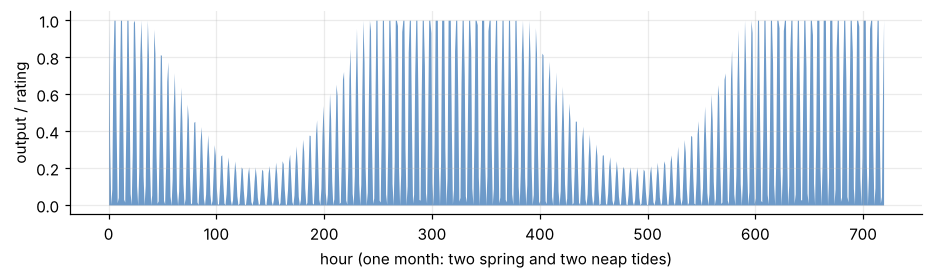

tidal kW per m³/d,0.00,0.10,0.15
renewable,,,
90%,"2.5×, 12 h tank, 0.9 kWp","2×, 8 h tank, 0.9 kWp","2×, 8 h tank, 0.5 kWp"
95%,"3×, 16 h tank, 0.9 kWp","2.5×, 12 h tank, 0.7 kWp","2×, 12 h tank, 0.9 kWp"
99%,not reached,"3×, 16 h tank, 0.9 kWp","2.5×, 16 h tank, 0.9 kWp"


In [8]:
tide = tidal_year()
print(f"capacity factor {tide.mean():.2f}")
fig, ax = plt.subplots(figsize=(10, 2.4))
ax.fill_between(np.arange(30 * 24), tide[:30 * 24], color=BLUE, lw=0, alpha=0.7)
ax.set_xlabel("hour (one month: two spring and two neap tides)"); ax.set_ylabel("output / rating")
plt.show()
moon = pd.read_parquet(RES / "step8_sun_and_moon.parquet")
best = []
for target in (0.90, 0.95, 0.99):
    for kw in (0.0, 0.10, 0.15):
        ok = moon[(moon.tidal_kw == kw) & (moon.renewable_fraction >= target)].sort_values(["storage_h", "capacity", "pv_kwp"])
        r = ok.iloc[0] if len(ok) else None
        best.append({"renewable": f"{target:.0%}", "tidal kW per m³/d": kw,
                     "design": "not reached" if r is None else f"{r.capacity:g}×, {r.storage_h:g} h tank, {r.pv_kwp:g} kWp",
                     "reached": None if r is None else round(r.renewable_fraction, 3)})
pd.DataFrame(best).pivot(index="renewable", columns="tidal kW per m³/d", values="design")

A turbine supplying about a quarter of the energy (0.10 kW per m³/day) reaches 90 % renewable with
a **2× plant and an 8-hour tank** — half the tank of PV alone. Most sites have no strong current;
where one exists, it buys a smaller plant and a smaller tank.

## 7. Per 1,000 m³ a day

In [9]:
saved = (cfg.sec - lp.grid_kwh_m3) * 365          # MWh a year per 1,000 m3/day
print(f"design: {0.7 * 1000:.0f} kWp of PV, a {16 / 24 * 1000:.0f} m³ tank, a {3 * 1000:,} m³/day plant running about 8 h a day")
print(f"grid electricity: {cfg.sec * 365:,.0f} -> {lp.grid_kwh_m3 * 365:,.0f} MWh a year (saves {saved:,.0f} MWh)")
print(f"CO2 avoided: {saved * 0.4:,.0f}-{saved * 0.7:,.0f} t a year at 0.4-0.7 kg per grid kWh")

design: 700 kWp of PV, a 667 m³ tank, a 3,000 m³/day plant running about 8 h a day
grid electricity: 1,190 -> 83 MWh a year (saves 1,107 MWh)
CO2 avoided: 443-775 t a year at 0.4-0.7 kg per grid kWh


## 8. Test your own plant log

The tide test of notebook 03 is in the package as `series_test`, and in the service at
[`/sun/test`](https://chemai-tr2c.onrender.com/sun/). It takes any signal with a time stamp — a
fouling rate, a pressure, a turbidity — and asks whether it is locked to the tide (or, with
`kind="clock"`, to the time of day), with the placebo periods beside every answer.

Here, two made-up logs: one with a tide in it, one with a daily wave (what a solar plant has by
design). The tide test must find the first and ignore the second.

In [10]:
from chemai.evaluation.tide_test import series_test

def made_up_log(wave, seed=3, runs=10, days=6):
    rng, out = np.random.default_rng(seed), []
    for k in range(runs):
        t = pd.Timestamp("2014-01-06") + pd.Timedelta(days=9 * k) + pd.to_timedelta(np.arange(0, days * 24, 0.5), unit="h")
        th = np.asarray((t - pd.Timestamp("2000-01-01")) / pd.Timedelta(hours=1))
        e = np.zeros(len(t))
        for i in range(1, len(t)):
            e[i] = 0.8 * e[i - 1] + 0.6 * rng.standard_normal()
        y = 2 + 0.25 * e
        y += 0.25 * np.cos(2 * np.pi * th / 12.4206 + 1) if wave == "tide" else 0.25 * np.cos(2 * np.pi * (t.hour - 14) / 24)
        out.append(pd.DataFrame({"t": t, "value": y, "run": f"run {k + 1}"}))
    return pd.concat(out, ignore_index=True)

rows = {}
for wave in ("tide", "daily"):
    log = made_up_log(wave)
    for kind in ("tide", "clock"):
        r = series_test(log, kind=kind, n_surrogates=499)
        rows[(f"a {wave} wave", kind)] = {"verdict": r["verdict"], "p": r["p_value"], "placebo p": r["placebo_p_value"]}
pd.DataFrame(rows).T

verdict      p placebo p
a tide wave  tide       locked  0.002      0.65
             clock  not locked  0.916     0.662
a daily wave tide   not locked  0.286     0.488
             clock      locked  0.002     0.476

For your own log: a CSV with columns `t` (local standard time), `value` and optionally `run`, at
least 100 points over 3 days, then

```python
log = pd.read_csv("my_log.csv", parse_dates=["t"])
series_test(log, kind="tide")
```

"Not locked" on a short or noisy log is not proof of absence — the answer carries the share of the
variance a wave would have needed to beat chance.

## What this is not

A cost optimum (no prices), a site design (a synthetic year), or evidence about the RO membranes under
daily stops (only the UF was in the record; the literature says a flush at each stop matters). What it
is: the physical sizes a plant needs to run mostly on the sun, built on a membrane result that was
declared and tested first.